# Modelos y validación

**Emisión:** al final del día D se pronostican las 24 horas del día D+1 (así se programa la energía en Colombia). **Partición:** entrenamiento octubre 2020 – diciembre 2024 con purga de 48 h; prueba enero 2025 – octubre 2026, usada una sola vez. **Validación:** 5 folds de ventana creciente con separación de 48 h.

**Modelos (7):**
- Tradicionales: **persistencia** (misma hora de ayer), **estacional** (misma hora de la semana pasada) y **promedio por hora y día de la semana**.
- Machine Learning: **Ridge** (perfiles hora × tipo de día, rezagos y calor), **random forest relativo**, **XGBoost relativo** e **híbrido Ridge + XGBoost** que corrige el residuo relativo de Ridge.

**Objetivo relativo (la idea central).** La primera versión entrenaba los árboles con la demanda en MWh y en la prueba fallaron: con demanda récord, un árbol no puede predecir valores mayores a los que vio. En la versión 2, los árboles aprenden la **forma relativa** $y_t / \\bar y_{7d}$ (demanda dividida por la media de los 7 días anteriores) con predictoras también relativas; el pronóstico es $\\hat y_t = \\bar y_{7d} \\times \\hat r_t$. El nivel lo lleva la media reciente; el árbol solo aprende cómo el calor, la hora y los festivos deforman ese nivel.

**Ajuste de hiperparámetros:** grillas pequeñas para todos los modelos de ML, elegidas con la validación.

**Nota:** en este capítulo y los dos siguientes, "el elegido" es el **mejor benchmark** según la regla. El modelo original (ATER, capítulo 5) se compara contra todos ellos en el capítulo 6.

**Regla fijada de antemano:** gana el menor MSE medio en validación; si la diferencia con el segundo es menor de 1 %, desempata el CSI de horas pico (> percentil 95 de entrenamiento). La prueba solo confirma.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar(); import pipeline_energia as P
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B", "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A"}

In [2]:
todas = pd.read_csv(R + "validacion_todas_config.csv")
todas.groupby(["modelo", "config"])[["MSE", "MAPE"]].mean().round(2)

MSE  MAPE
modelo                                     config                 
Estacional (misma hora semana pasada)      -         6396.58  5.12
Híbrido Ridge + XGBoost (residuo relativo) d3_n300   2208.69  2.97
                                           d4_n400   2220.20  2.96
                                           d6_n600   2244.84  2.96
Persistencia (misma hora de ayer)          -         5517.30  4.62
Promedio por hora y día                    -        10873.11  7.04
Random forest (relativo)                   hoja20    2179.14  2.87
                                           hoja5     2110.94  2.81
Ridge (lineal)                             a10       2459.67  3.21
                                           a100      2439.83  3.19
XGBoost (relativo)                         d3_n300   2224.67  2.94
                                           d6_n600   2144.39  2.83

In [3]:
val = pd.read_csv(R + "validacion.csv"); e = json.load(open(R + "eleccion.json"))
print("Configuración elegida por modelo:", e["configuraciones"]); print("ELEGIDO POR LA REGLA:", e["elegido"])
val[["modelo", "config", "MSE", "RMSE", "MAPE", "AUC_pico", "POD", "FAR", "CSI", "mejora_MSE_vs_Persistencia_%", "mejora_MSE_vs_Estacional_%"]].round(3)

Configuración elegida por modelo: {'Híbrido Ridge + XGBoost (residuo relativo)': 'd3_n300', 'Random forest (relativo)': 'hoja5', 'Ridge (lineal)': 'a100', 'XGBoost (relativo)': 'd6_n600'}
ELEGIDO POR LA REGLA: Random forest (relativo)


modelo,config,MSE,RMSE,MAPE,AUC_pico,POD,FAR,CSI,mejora_MSE_vs_Persistencia_%,mejora_MSE_vs_Estacional_%
Random forest (relativo),hoja5,2.111,"45,4","2,81","0,967","0,299","0,151","0,254","61,74","67,00"
XGBoost (relativo),d6_n600,2.144,"45,8","2,83","0,959","0,297","0,555","0,252","61,13","66,48"
Híbrido Ridge + XGBoost (residuo relativo),d3_n300,2.209,"46,6","2,97","0,972","0,228","0,133","0,205","59,97","65,47"
Ridge (lineal),a100,2.440,"48,9","3,19","0,967","0,215","0,133","0,194","55,78","61,86"
Persistencia (misma hora de ayer),-,5.517,"74,1","4,62","0,937","0,400","0,599","0,278","0,00","13,75"
Estacional (misma hora semana pasada),-,6.397,"79,1","5,12","0,901","0,345","0,645","0,233","-15,94","0,00"
Promedio por hora y día,-,10.873,"101,2","7,04","0,911","0,000","0,000","0,000","-97,07","-69,98"


In [4]:
t = val.sort_values("MSE"); print("Diferencia relativa de MSE entre el 1.º y el 2.º: %.2f %%" % (100*(t.MSE.iloc[1]/t.MSE.iloc[0]-1)))
fold = todas.merge(pd.DataFrame(e["configuraciones"].items(), columns=["modelo", "config"]).assign(ok=1), on=["modelo", "config"], how="left")
fold = fold[(fold.config == "-") | (fold.ok == 1)]
fold.pivot(index="modelo", columns="fold", values="MAPE").round(2)

Diferencia relativa de MSE entre el 1.º y el 2.º: 1.58 %


fold,0,1,2,3,4
modelo,,,,,
Estacional (misma hora semana pasada),"4,70","5,21","4,32","5,42","5,94"
Híbrido Ridge + XGBoost (residuo relativo),"3,15","3,03","2,49","2,83","3,36"
Persistencia (misma hora de ayer),"4,49","4,69","4,41","4,44","5,08"
Promedio por hora y día,"5,46","5,05","6,79","8,75","9,13"
Random forest (relativo),"2,55","3,00","2,43","2,75","3,31"
Ridge (lineal),"3,08","3,26","2,72","3,16","3,75"
XGBoost (relativo),"2,66","3,06","2,42","2,71","3,29"


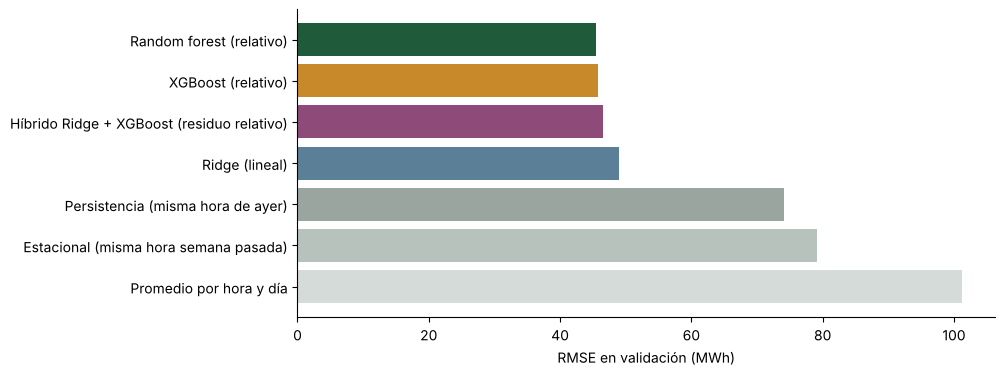

In [5]:
fig, ax = plt.subplots(figsize=(9, 4)); v = val.sort_values("MSE", ascending=False)
ax.barh(v.modelo, v.RMSE, color=[COL[m] for m in v.modelo]); ax.set_xlabel("RMSE en validación (MWh)"); plt.show()

 **Lectura.**

- Todos los modelos de ML le ganan con amplitud a los tres tradicionales en validación: entre 56 y 62 % menos MSE que la persistencia y entre 62 y 67 % menos que la misma hora de la semana pasada.
- Por la regla gana el **random forest relativo** (MSE 2.111, MAPE 2,81 %), con una ventaja de 1,58 % sobre el XGBoost relativo (MSE 2.144), por encima del umbral de empate de 1 %.
- El híbrido Ridge + XGBoost queda tercero (MSE 2.209) y Ridge cuarto (2.440).
- En los 5 folds, los cuatro modelos de ML tienen menos error que los tres tradicionales. Entre ellos, el random forest y el XGBoost relativos se alternan el primer lugar de un fold a otro: son prácticamente equivalentes.